# 01 · Загрузка и профилирование Online Retail II

Шаги 1–2 плана `case_ltv`. Источник: Chen, D. (2012), UCI ML Repository, DOI 10.24432/C5CG6D, CC BY 4.0. Чистка и её журнал — в `src/data.py`.

In [1]:
import sys
sys.path.insert(0, '../..')      # корень репо: paths.py
sys.path.insert(0, '../src')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from paths import CASE_LTV, figures
from data import load_raw, load_clean
FIG = figures(CASE_LTV); FIG.mkdir(parents=True, exist_ok=True)
raw = load_raw()
tx, log = load_clean()
print(raw.shape, tx.shape)

(1067371, 8) (794078, 10)


## Пропуски в сырых данных

In [2]:
na = raw.isna().mean().round(4).rename('null_share').to_frame()
na

,null_share
invoice,0.0000
stock_code,0.0000
description,0.0041
quantity,0.0000
date,0.0000
price,0.0000
customer_id,0.2277
country,0.0000


Гейт из журнала: доля пропусков в `invoice`, `date`, `price` < 20 %. `customer_id` пропущен у ~23 %, строки удаляются, доля фиксируется ниже.

In [3]:
assert (na.loc[['invoice', 'date', 'price'], 'null_share'] < 0.20).all()
print('null customer_id, доля сырых строк:', round(na.loc['customer_id', 'null_share'], 4))

null customer_id, доля сырых строк: 0.2277


## Журнал чистки

Каждая строка — шаг по порядку. Порядок влияет на числа (дубликаты удаляются до пропусков ID).

In [4]:
log

,step,rows_removed,rows_left,customers_left
0,raw,0,1067371,5942
1,exact duplicates,34335,1033036,5942
2,null customer_id,235151,797885,5942
3,null date,0,797885,5942
4,service stock codes,3660,794225,5876
5,price <= 0,60,794165,5875
6,customers with cancellations only,87,794078,5852


Отмены (счета с префиксом `C`) не удаляются, остаются отрицательными строками: нужны для net-выручки. Служебные коды (`POST`, `DOT`, `M`, `D`, `C2`, `BANK CHARGES`, `AMAZONFEE`, подарочные ваучеры `gift_*` и др.) — не покупка товара клиентом.

In [5]:
print('период:', tx.date.min(), '→', tx.date.max())
months = (tx.date.max() - tx.date.min()).days / 30.44
n_cust = tx.customer_id.nunique()
print(f'история {months:.1f} мес, клиентов {n_cust}, строк {len(tx)}')
assert n_cust >= 1000 and months >= 18      # гейты качества данных

период: 2009-12-01 07:45:00 → 2011-12-09 12:50:00
история 24.2 мес, клиентов 5852, строк 794078


## Отмены и возвраты

In [6]:
sales = tx[~tx.is_cancel]; canc = tx[tx.is_cancel]
print('строк отмен:', len(canc), f'({len(canc)/len(tx):.1%})')
print('выручка продаж:', round(sales.revenue.sum()), ' отмен:', round(canc.revenue.sum()),
      f' доля отмен: {-canc.revenue.sum()/sales.revenue.sum():.1%}')
# возврат без исходной покупки в данных = покупка до начала окна
first = sales.groupby('customer_id').date.min()
early = canc.assign(first=canc.customer_id.map(first)).query('date < first')
print('отмен раньше первой покупки клиента:', len(early))

строк отмен: 17499 (2.2%)


выручка продаж: 17068583  отмен: -708547  доля отмен: 4.2%
отмен раньше первой покупки клиента: 557


## Крупнейшие строки (выбросы)

In [7]:
pd.concat([tx.nlargest(5, 'revenue'), tx.nsmallest(5, 'revenue')])[['invoice','stock_code','quantity','price','revenue','customer_id','date']]

,invoice,stock_code,quantity,price,revenue,customer_id,date
793611,581483,23843,80995,2.08,168469.6,16446,2011-12-09 09:15:00
431756,541431,23166,74215,1.04,77183.6,12346,2011-01-18 10:01:00
551024,556444,22502,60,649.50,38970.0,15098,2011-06-10 15:28:00
340072,530715,84347,9360,1.69,15818.4,15838,2010-11-04 11:36:00
173701,511465,15044A,3500,2.55,8925.0,18008,2010-06-08 12:59:00
793612,C581484,23843,-80995,2.08,-168469.6,16446,2011-12-09 09:27:00
431761,C541433,23166,-74215,1.04,-77183.6,12346,2011-01-18 10:17:00
504815,C550456,21108,-3114,2.10,-6539.4,15749,2011-04-18 13:08:00
504813,C550456,85123A,-1930,2.55,-4921.5,15749,2011-04-18 13:08:00
504811,C550456,48185,-670,6.75,-4522.5,15749,2011-04-18 13:08:00


Две пары «заказ — полная отмена»: клиент 16446 (80 995 шт., ±168 469,6 £, обе строки 2011-12-09) и клиент 12346 (74 215 шт., ±77 183,6 £, отмена в тот же месяц). Нетто 16446 равно нулю, у 12346 остаётся его обычная история. Фильтр «отбросить отрицательные» оставил бы только положительную половину и завысил бы выручку обоих клиентов.

In [8]:
big = tx.loc[tx.revenue.abs() > 100_000]
print(big.groupby('customer_id').revenue.sum())

customer_id
16446    0.0
Name: revenue, dtype: float64


## Распределения: покупки на клиента и размер чека

Покупка = уникальный `invoice` без префикса `C`.

count    5852.000000
mean        6.253247
std        12.749286
min         1.000000
25%         1.000000
50%         3.000000
75%         7.000000
max       373.000000
dtype: float64
ровно 1 покупка: 27.6%  2+: 72.4%


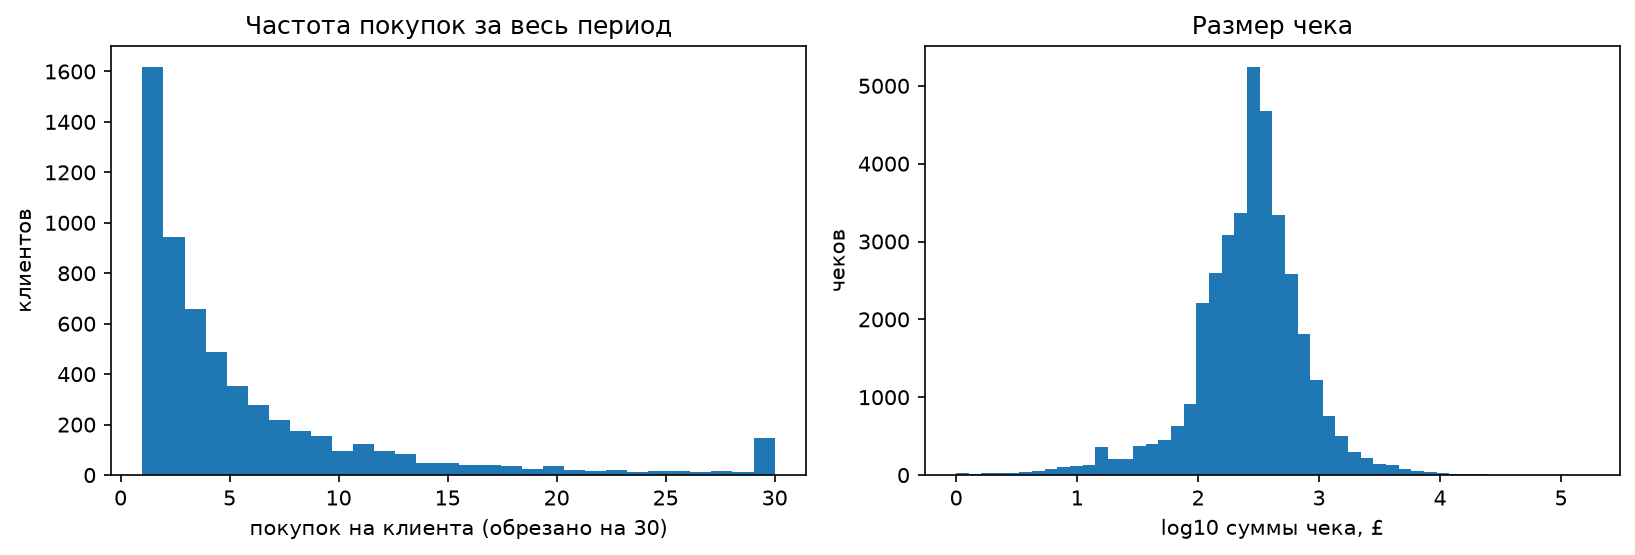

In [9]:
inv = sales.groupby(['customer_id', 'invoice']).agg(date=('date','min'), amount=('revenue','sum')).reset_index()
n_purch = inv.groupby('customer_id').size()
print(n_purch.describe())
print('ровно 1 покупка:', f'{(n_purch==1).mean():.1%}', ' 2+:', f'{(n_purch>=2).mean():.1%}')
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), dpi=150)
ax[0].hist(n_purch.clip(upper=30), bins=30)
ax[0].set(xlabel='покупок на клиента (обрезано на 30)', ylabel='клиентов', title='Частота покупок за весь период')
ax[1].hist(np.log10(inv.amount.clip(lower=1)), bins=50)
ax[1].set(xlabel='log10 суммы чека, £', ylabel='чеков', title='Размер чека')
fig.tight_layout(); fig.savefig(FIG / '01-purchases-and-basket.png'); plt.show()

Слева: доля клиентов с одной покупкой — размер сегмента B (журнал решений, 2026-09-13), справа: распределение чека скошено вправо, оптимально в логарифме.

## Активность во времени

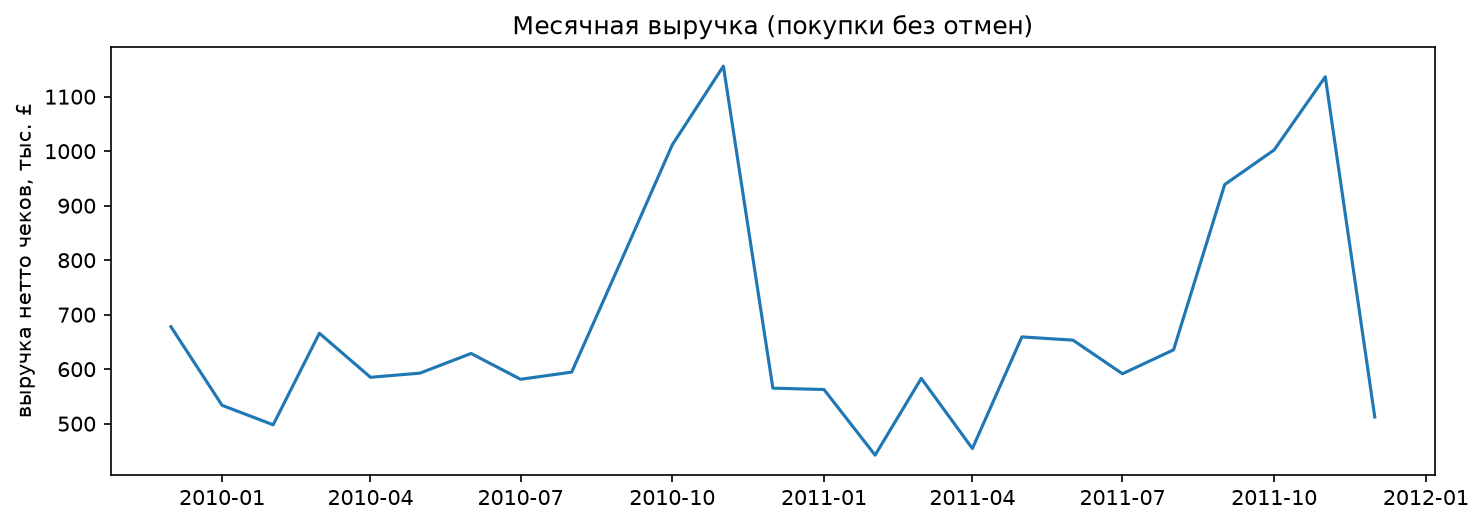

date,2009-12-01,2010-01-01,2010-02-01,2010-03-01,2010-04-01,2010-05-01,2010-06-01,2010-07-01,2010-08-01,2010-09-01,...,2011-03-01,2011-04-01,2011-05-01,2011-06-01,2011-07-01,2011-08-01,2011-09-01,2011-10-01,2011-11-01,2011-12-01
orders,1497.0,959.0,1093.0,1509.0,1315.0,1365.0,1479.0,1362.0,1276.0,1659.0,...,1312.0,1139.0,1544.0,1390.0,1321.0,1267.0,1739.0,1903.0,2642.0,776.0
revenue,677916.0,533713.0,497938.0,665974.0,585127.0,592734.0,628809.0,581488.0,594561.0,805545.0,...,583144.0,454441.0,659242.0,653265.0,591604.0,635514.0,938753.0,1002327.0,1136534.0,512228.0


In [10]:
m = inv.set_index('date').resample('MS').agg(orders=('amount','size'), revenue=('amount','sum'))
fig, ax = plt.subplots(figsize=(10, 3.6), dpi=150)
ax.plot(m.index, m.revenue / 1e3)
ax.set(ylabel='выручка нетто чеков, тыс. £', title='Месячная выручка (покупки без отмен)')
fig.tight_layout(); fig.savefig(FIG / '02-monthly-revenue.png'); plt.show()
m.round(0).T

Максимум в ноябре обоих лет (2010-11: 1,16 млн £, 2011-11: 1,14 млн £) — сезонность подарочного ритейла. Декабрь 2011 неполный (данные до 9-го числа), поэтому падение в конце ряда не является оттоком. Cutoff для calibration/holdout выбираем с учётом обоих эффектов.

In [11]:
# Состав по странам
c = tx.groupby('country').agg(customers=('customer_id','nunique'), revenue=('revenue','sum'))
c['rev_share'] = (c.revenue / c.revenue.sum()).round(3)
c.sort_values('revenue', ascending=False).head(6)

,customers,revenue,rev_share
country,,,
United Kingdom,5334,13662394.57,0.835
EIRE,3,567577.15,0.035
Netherlands,22,546095.43,0.033
Germany,107,374573.51,0.023
France,93,291744.07,0.018
Australia,15,166282.15,0.010
